# Removing distractors in a non-stationary problem

Can Autostep with the changes from `01_distractors.ipynb` (centered hidden units, with a matching centered backward pass,
and input weights starting near 0) remove the impact of distractor connections when the problem keeps changing?

**Problem.** 2-task simple multi-GEOFF, as in Question 3 of `01_distractors.ipynb`. Each task has 21 inputs, 10
zero-threshold teacher LTUs, and 10 outputs plus $N(0, 1)$ noise. The inputs and every teacher weight are random
$\pm 1$ signs, so each LTU fires with probability 1/2 and each output's signal has variance about 2.5. It is
non-stationary: every 1000 steps, one task (chosen at random) has the columns of its output weights permuted, which
relabels which teacher features feed which outputs. Each task changes about every 2000 steps.

**Network.** 42 inputs → 20 LTU hidden units (10 per task) → 20 linear outputs, each layer with a bias. Every hidden
unit reads its own task's inputs and feeds its own task's outputs. Distractors: odd hidden units also read the other
task's inputs (210), and even hidden units also feed the other task's outputs (100).

**Learners.** Autostep (each layer its own linear problem) on $\frac{1}{2}\|\hat{y} - y\|^2$, with every step-size
starting at $\alpha_0 = 10^{-8}$, meta step-size 0.01 and $\tau = 10^4$. Output weights and biases start at 0.
1. *Ours*: each hidden unit sends $h - m$, where $m$ is its running mean firing rate (an EMA at rate $10^{-3}$), and
   the backward pass uses the matching gradient $\sigma'(z)\,x - \mathbb{E}[\sigma'(z)\,x]$. Input weights start at
   $U(-\alpha_0, \alpha_0)$.
2. *Standard Autostep*: hidden units send $h$, and input weights start LeCun uniform.
3. *Ours without distractors*: ours, in the same network minus every distractor.
4. *Standard Autostep without distractors*: standard Autostep in that same network.

1M steps and 30 seeds; seed $s$ gives every learner the same teacher and the same perturbations. Everything is
recorded at step 1, then averaged over each window of 4000 steps. The learning curves show the RMSE (its minimum, the
noise, is 1), mean $\pm 2$ standard errors over seeds.

**Hypotheses**, on the excess MSE (above the noise floor) averaged over the last 10% of training (about 100
perturbations), pooled over seeds:
- **H1**, ours removes the distractors' impact: ours is at most 1% above ours without distractors.
- **H2**, there is an impact to remove: standard Autostep is more than 1% above standard Autostep without
  distractors.

**Diagnostic**, fixed in advance: for ours, the distractors' $\beta = \ln(\alpha)$, the log step-size, and $|w|$
against the useful weights', to see whether the distractors stay quiet while the useful weights keep re-adapting.

In [1]:
from typing import NamedTuple

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd
from phd.jax_core.tasks.simple_multi_geoff import SimpleMultiGEOFFTask
from phd.jax_core.utils import stack_pytrees

sns.set_theme('notebook', 'whitegrid')
%matplotlib inline

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_TASKS = 2
N_INPUTS_PER_TASK = 21
N_TEACHER_LTUS_PER_TASK = 10
N_OUTPUTS_PER_TASK = 10
NOISE_STD = 1.0
PERTURB_PERIOD = 1000                # steps between perturbations, each of one task chosen at random

# --- Network ---
N_HIDDEN_PER_TASK = 10

# --- Autostep ---
INIT_STEP_SIZE = 1e-8
META_STEP_SIZE = 0.01
TAU = 1e4
EMA_RATE = 1e-3                      # rate of the hidden units' running means (used by ours)

# --- Training ---
NUM_STEPS = 1_000_000
N_SEEDS = 30
N_WINDOWS = 250                      # each window records the mean of the loss and of every recorded beta and |w|

# --- Hypotheses ---
FINAL_FRACTION = 0.1                 # the loss is compared over the last 10% of training ...
LOSS_TOLERANCE = 0.01                # ... with this relative tolerance

In [3]:
LAYERS = ('w1', 'w2')
N_HIDDEN = N_TASKS * N_HIDDEN_PER_TASK
N_OUTPUTS = N_TASKS * N_OUTPUTS_PER_TASK

input_task = np.repeat(np.arange(N_TASKS), N_INPUTS_PER_TASK)
hidden_task = np.repeat(np.arange(N_TASKS), N_HIDDEN_PER_TASK)
output_task = np.repeat(np.arange(N_TASKS), N_OUTPUTS_PER_TASK)
reads_other_inputs = np.arange(N_HIDDEN) % 2 == 1        # odd hidden units
feeds_other_outputs = ~reads_other_inputs                 # even hidden units


def with_bias_column(mask, bias):
    # The last column of each weight matrix reads the constant-1 input.
    return np.concatenate([mask, np.full((mask.shape[0], 1), bias)], axis=1)


# Masks are shaped like the weight matrices: w1 is (hidden, inputs + 1), w2 is (outputs, hidden + 1).
same_task = {'w1': hidden_task[:, None] == input_task[None, :],
             'w2': output_task[:, None] == hidden_task[None, :]}
USEFUL = {k: with_bias_column(m, False) for k, m in same_task.items()}
DISTRACTORS = {'w1': with_bias_column(~same_task['w1'] & reads_other_inputs[:, None], False),
               'w2': with_bias_column(~same_task['w2'] & feeds_other_outputs[None, :], False)}
BLOCK_SPARSE = {k: with_bias_column(m, True) for k, m in same_task.items()}      # the useful weights and the biases
MASKS = {'with distractors': {k: BLOCK_SPARSE[k] | DISTRACTORS[k] for k in LAYERS},
         'no distractors': BLOCK_SPARSE}

for k in LAYERS:
    print(f'{k}: {USEFUL[k].sum()} useful, {DISTRACTORS[k].sum()} distractors, {BLOCK_SPARSE[k].shape[0]} biases')

w1: 420 useful, 210 distractors, 20 biases
w2: 200 useful, 100 distractors, 20 biases


## Learner

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


class Learner(NamedTuple):
    w: dict                   # {'w1': ..., 'w2': ...}; masked-out weights stay at exactly 0 (their gradient is 0)
    opt: IDBDState
    hidden_mean: jax.Array    # each hidden unit's running mean firing rate
    hidden_slope: jax.Array   # running mean of sigma'(z) x, each hidden unit's derivative w.r.t. each input weight


def init_learner(key, masks, ours):
    # Input weights: U(-INIT_STEP_SIZE, INIT_STEP_SIZE) for ours, LeCun uniform over each unit's inputs otherwise. Both
    # scale the same draw.
    fan_in = masks['w1'][:, :-1].sum(1, keepdims=True)
    bound = INIT_STEP_SIZE if ours else np.sqrt(3.0 / fan_in)
    w1 = jax.random.uniform(key, masks['w1'].shape, minval=-1.0, maxval=1.0) * bound * masks['w1']
    w = {'w1': w1.at[:, -1].set(0.0), 'w2': jnp.zeros(masks['w2'].shape)}
    # A zero-threshold LTU with symmetric inputs fires with probability 1/2, so the means start out exact. The slope
    # starts at sigma'(0) E[x]: 0 for the zero-mean inputs, 1/4 for the bias.
    return Learner(w, OPTIMIZER.init(w), jnp.full(N_HIDDEN, 0.5), jnp.zeros(masks['w1'].shape).at[:, -1].set(0.25))


def forward(w, x, learner, masks, ours):
    # Returns the prediction, each weight's source values (what Autostep normalizes by), and the new running means.
    x = jnp.append(x, 1.0)
    w1 = w['w1'] * masks['w1']
    z = w1 @ x
    h = ltu(z)

    # Running means, updated with this sample before they are used. No gradient flows through them.
    mean = learner.hidden_mean + EMA_RATE * (jax.lax.stop_gradient(h) - learner.hidden_mean)
    sigma_prime = jax.lax.stop_gradient(jax.nn.sigmoid(z) * (1.0 - jax.nn.sigmoid(z)))     # the LTU's surrogate slope
    slope = learner.hidden_slope + EMA_RATE * (sigma_prime[:, None] * x[None, :] - learner.hidden_slope)
    if ours:
        # Send h - m, with the gradient of h - E[h]: each input weight's derivative becomes sigma'(z) x - slope. The
        # correction leaves the value unchanged.
        correction = jnp.sum(slope * w1, axis=1)
        h = h - mean - correction + jax.lax.stop_gradient(correction)

    h = jnp.append(h, 1.0)
    y_hat = (w['w2'] * masks['w2']) @ h
    return y_hat, ({'w1': x[None], 'w2': h[None]}, mean, slope)


def learner_step(learner, x, y, masks, ours):
    # One online Autostep update. Returns the new learner and the squared error summed over outputs.
    def loss_fn(w):
        y_hat, aux = forward(w, x, learner, masks, ours)
        return 0.5 * jnp.sum((y_hat - y) ** 2), aux

    (loss, (source_values, mean, slope)), grads = jax.value_and_grad(loss_fn, has_aux=True)(learner.w)
    updates, opt = OPTIMIZER.update((grads, None, source_values), learner.opt, learner.w)
    w = {k: learner.w[k] + updates[k] for k in LAYERS}
    return Learner(w, opt, mean, slope), 2.0 * loss

## Training

In [5]:
WINDOW = NUM_STEPS // N_WINDOWS
RECORDED = {'useful': USEFUL, 'distractors': DISTRACTORS}


def recorded_values(learner):
    # beta (log step-size) and |w| of the useful weights and of the distractors, flattened per layer.
    return {group: {k: {'beta': learner.opt.beta[k][mask[k]], 'w': jnp.abs(learner.w[k])[mask[k]]} for k in LAYERS}
            for group, mask in RECORDED.items()}


def train(key, task, masks, ours):
    # Step 1 on its own, then NUM_STEPS online steps in windows. Returns the per-output MSE, and the recorded weights'
    # beta (log step-size) and |w|: at step 1, then averaged over every window.
    def one_step(carry, _):
        learner, task, total = carry
        task, (x, y) = task.generate_batch(1)
        learner, sq_err = learner_step(learner, x[0], y[0], masks, ours)
        total = jax.tree.map(jnp.add, total, recorded_values(learner))
        return (learner, task, total), sq_err

    def window(carry, _):
        learner, task = carry
        zeros = jax.tree.map(jnp.zeros_like, recorded_values(learner))
        (learner, task, total), sq_err = jax.lax.scan(one_step, (learner, task, zeros), length=WINDOW)
        return (learner, task), (sq_err.mean() / N_OUTPUTS, jax.tree.map(lambda t: t / WINDOW, total))

    task, (x, y) = task.generate_batch(1)
    learner, sq_err = learner_step(init_learner(key, masks, ours), x[0], y[0], masks, ours)
    _, (mse, values) = jax.lax.scan(window, (learner, task), length=N_WINDOWS)
    first = (sq_err / N_OUTPUTS, recorded_values(learner))
    return jax.tree.map(lambda f, v: jnp.concatenate([f[None], v]), first, (mse, values))


def seeds():
    # Init keys and teachers. Seed s uses teacher s (and its perturbations) and init key s for every learner, so runs
    # are paired.
    tasks = stack_pytrees([
        SimpleMultiGEOFFTask(N_TASKS, perturb_period=PERTURB_PERIOD, n_features_per_task=N_INPUTS_PER_TASK,
                             n_hidden_per_task=N_TEACHER_LTUS_PER_TASK, n_outputs_per_task=N_OUTPUTS_PER_TASK,
                             noise_std=NOISE_STD, seed=s)
        for s in range(N_SEEDS)])
    return jax.random.split(jax.random.PRNGKey(0), N_SEEDS), tasks


def run(problem, ours):
    # Trains one learner (ours, or standard Autostep) on `problem` (a key of MASKS) on every seed, vmapped into one
    # scan. Returns the excess MSE and the RMSE (seed, step 1 + window), and values[group][layer][quantity] (seed,
    # step 1 + window, weight).
    keys, tasks = seeds()
    mse, values = jax.jit(jax.vmap(lambda key, task: train(key, task, MASKS[problem], ours)))(keys, tasks)
    mse = np.asarray(mse)
    return {'excess_mse': mse - NOISE_STD ** 2, 'rmse': np.sqrt(mse), **jax.tree.map(np.asarray, values)}

## Results

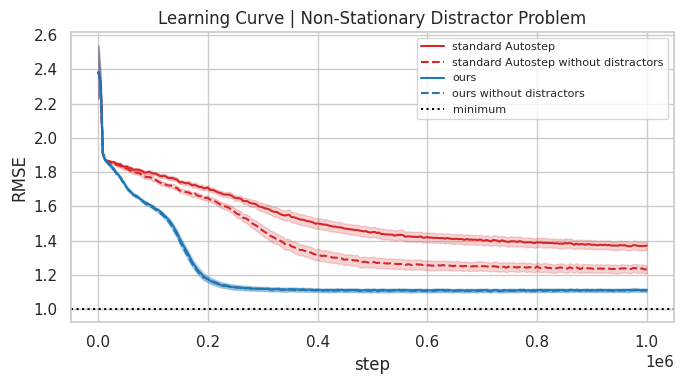

standard Autostep                      excess MSE 0.8857
standard Autostep without distractors  excess MSE 0.5313
ours                                   excess MSE 0.2343
ours without distractors               excess MSE 0.2295
H1, ours vs ours without distractors: +2.1% (± 9.9%): failed
H2, standard Autostep vs standard Autostep without distractors: +66.7% (± 10.5%): held


In [6]:
runs = {'standard Autostep': run('with distractors', ours=False),
        'standard Autostep without distractors': run('no distractors', ours=False),
        'ours': run('with distractors', ours=True),
        'ours without distractors': run('no distractors', ours=True)}
# Color by learner; dashed without distractors.
STYLES = {'standard Autostep': ('tab:red', '-'), 'standard Autostep without distractors': ('tab:red', '--'),
          'ours': ('tab:blue', '-'), 'ours without distractors': ('tab:blue', '--')}

steps = 1 + np.arange(N_WINDOWS + 1) * WINDOW     # step 1, then the end of every window
plt.figure(figsize=(7, 4))
for label, res in runs.items():
    mean = res['rmse'].mean(0)
    sem = res['rmse'].std(0) / np.sqrt(N_SEEDS)
    color, linestyle = STYLES[label]
    plt.plot(steps, mean, color=color, ls=linestyle, lw=1.5, label=label)
    plt.fill_between(steps, mean - 2 * sem, mean + 2 * sem, color=color, alpha=0.2)
plt.axhline(NOISE_STD, color='black', lw=1.5, ls=':', label='minimum')
plt.xlabel('step')
plt.ylabel('RMSE')
plt.title('Learning Curve | Non-Stationary Distractor Problem')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Each seed's excess MSE over the last FINAL_FRACTION of training.
final = slice(-round(N_WINDOWS * FINAL_FRACTION), None)
loss = {label: res['excess_mse'][:, final].mean(1) for label, res in runs.items()}
for label, l in loss.items():
    print(f'{label:<38} excess MSE {l.mean():.4f}')


def gap(label, reference):
    # The per-seed gap to `reference` on the same seed, relative to the reference's mean: its mean and 2 SE.
    g = (loss[label] - loss[reference]) / loss[reference].mean()
    return g.mean(), 2 * g.std() / np.sqrt(N_SEEDS)


held = lambda ok: 'held' if ok else 'failed'
h1, h1_se = gap('ours', 'ours without distractors')
h2, h2_se = gap('standard Autostep', 'standard Autostep without distractors')
print(f'H1, ours vs ours without distractors: {h1:+.1%} (± {h1_se:.1%}): {held(h1 <= LOSS_TOLERANCE)}')
print(f'H2, standard Autostep vs standard Autostep without distractors: {h2:+.1%} (± {h2_se:.1%}): '
      f'{held(h2 > LOSS_TOLERANCE)}')

### Diagnostic: distractors against useful weights

Ours, in each layer: the mean of $\beta$ and the median of $|w|$, with the 5th to 95th percentile shaded, pooled over
seeds.

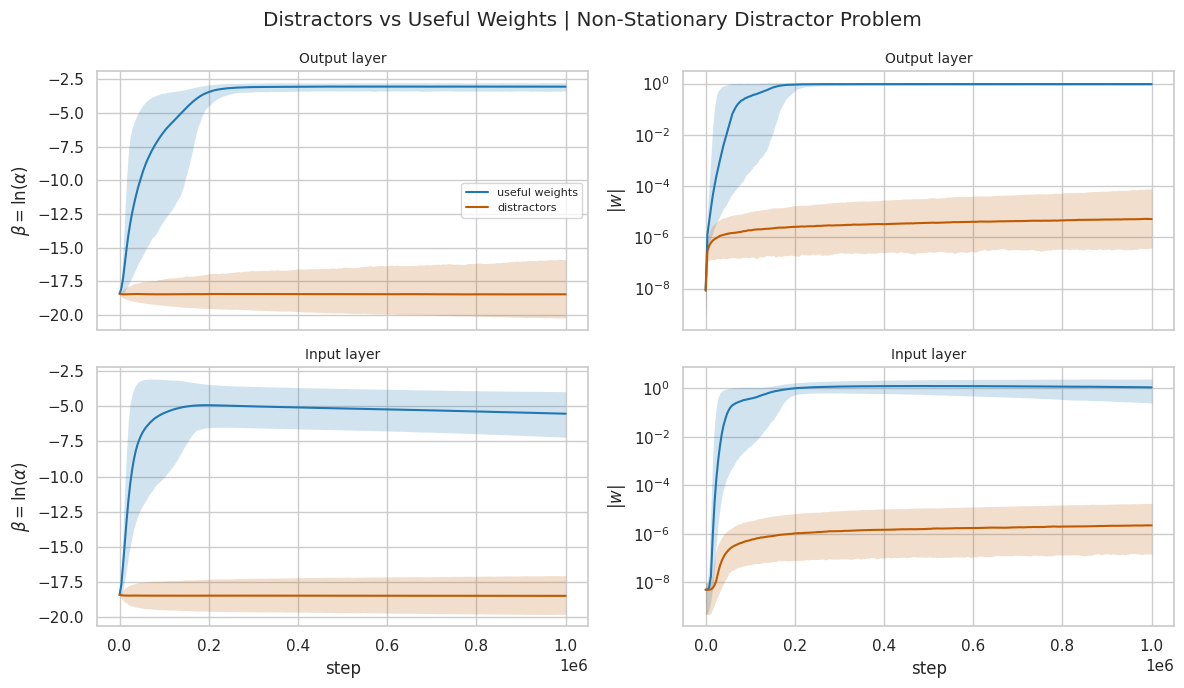

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
columns = [('beta', '$\\beta = \\ln(\\alpha)$', np.mean, 'linear'), ('w', '$|w|$', np.median, 'log')]
for row, (name, layer) in zip(axes, [('Output', 'w2'), ('Input', 'w1')]):
    for ax, (quantity, ylabel, center, yscale) in zip(row, columns):
        for (group, label), color in zip([('useful', 'useful weights'), ('distractors', 'distractors')],
                                         ('#1f77b4', '#c05a00')):
            v = runs['ours'][group][layer][quantity].transpose(1, 0, 2).reshape(len(steps), -1)
            ax.plot(steps, center(v, axis=1), color=color, lw=1.5, label=label)
            ax.fill_between(steps, *np.percentile(v, [5, 95], axis=1), color=color, alpha=0.2, lw=0)
        ax.set_yscale(yscale)
        ax.set_title(f'{name} layer', fontsize=10)
        ax.set_ylabel(ylabel)
for ax in axes[1]:
    ax.set_xlabel('step')
axes[0, 0].legend(fontsize=8)
fig.suptitle('Distractors vs Useful Weights | Non-Stationary Distractor Problem')
fig.tight_layout()
plt.show()

## Results

- **H1 failed, within noise.** Over the last 10% of training, ours has an excess MSE of 0.2343, +2.1% (± 9.9%, 2 SE
  over paired seeds) against ours without distractors (0.2295), above the 1% tolerance, though the two mean loss
  curves overlap for the whole run. The gap comes from a few seeds on which a learner plateaus by about 200k steps at
  an excess MSE of 0.32 to 0.45 instead of about 0.21: five seeds of ours and three of ours without distractors. On
  the other 24 seeds (a split made after the fact), ours is 2.7% (± 0.8%) *below* ours without distractors.
- **H2 held.** Standard Autostep is +66.7% (± 10.5%) above standard Autostep without distractors (0.8857 against
  0.5313), so the distractors hurt it badly.
- **Our changes also help without distractors.** Ours without distractors is 57% below standard Autostep without
  distractors (0.2295 against 0.5313). Of the gap between standard Autostep and ours (0.65), about half (0.30) comes
  from the changes themselves and half (0.35) from the distractors' cost to standard Autostep.
- **Diagnostic.** The useful weights' mean $\beta$ rises within 200k steps to about −3 in the output layer and −5 in
  the input layer, and stays near there (the input layer's drifts to −5.5 by 1M steps) while the problem keeps
  changing. The distractors' mean $\beta$ stays at its initial −18.4 in both layers, but their spread still widens
  (by 1M steps the 95th percentile reaches about −15.9 for the output distractors and −17.0 for the input
  distractors), and their median $|w|$ creeps up to about $5 \cdot 10^{-6}$ (output) and $2 \cdot 10^{-6}$ (input).
  Neither shows up as a consistent cost in the loss within 1M steps.